In [1]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import math

In [2]:
def turn(angle):
    rad = math.radians(angle)
    x_inc = math.cos(rad)
    y_inc = math.sin(rad)
    return np.array([x_inc, y_inc])

def forward(step, direction, positions):
    new_pos = positions[-1] + step * direction
    positions = np.append(positions, [new_pos], axis=0)
    positions = np.round(positions, decimals=3)
    return positions

In [3]:
def plot_gradient_path(positions, cmap_name="turbo"):
    n = len(positions) - 1

    segments = np.stack([positions[:-1], positions[1:]], axis=1)

    cmap = plt.get_cmap(cmap_name)
    colors = cmap(np.linspace(0, 1, n))

    lineCollection = LineCollection(segments, colors=colors, linewidth=1)

    _, ax = plt.subplots(figsize=(10, 10))
    ax.add_collection(lineCollection)

    ax.autoscale()
    ax.axis(False)
    ax.set_aspect("equal")
    plt.show()

In [4]:
def dragon_curve_sequence(n):
    seq = "L"
    for _ in range(n - 1):
        inv = seq[::-1].translate(str.maketrans("LR", "RL"))
        seq = seq + "L" + inv
    return seq

def write_commands(filename, level, step):
    seq = dragon_curve_sequence(level)
    with open(filename, "w") as f:
        for turn in seq:
            f.write(f"forward {step}\n")
            if turn == "L":
                f.write("turn 90\n")
            else:
                f.write("turn -90\n")

write_commands("dragon.txt", level=16, step=10)

In [5]:
commands_file = 'commands2.txt'

def turle_path(commands_file):
    positions = np.array([[0.0, 0.0]])
    current_angle = 0
    direction = turn(current_angle)

    with open(commands_file, 'r') as file:
        for line in file:
            command = line.split()

            if command[0] == 'forward':
                positions = forward(float(command[1]), direction, positions)
            elif command[0] == 'turn':
                current_angle += int(command[1])
                direction = turn(current_angle)

    return positions

path = turle_path(commands_file)

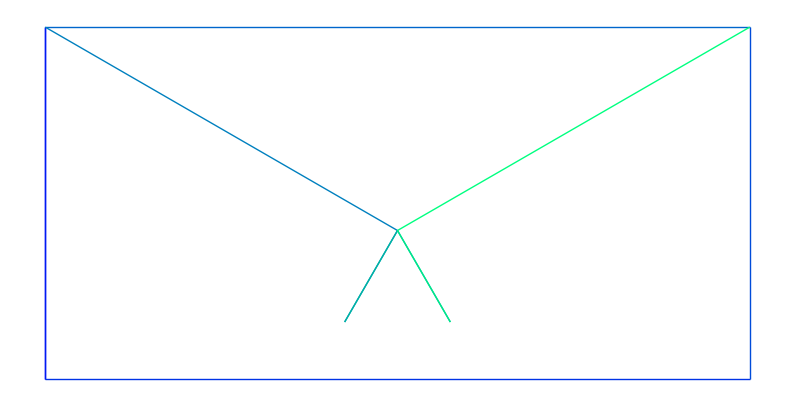

In [17]:
plot_gradient_path(path, 'winter')

In [ ]:
def create_dragon_path(level=17):
    seq = dragon_curve_sequence(level)

    positions = np.array([[0.0, 0.0]])
    current_angle = 0
    direction = turn(current_angle)

    for step in seq:
        if step == "L":            
            current_angle += 90
        else:
            current_angle -= 90
        direction = turn(current_angle)
        positions = forward(10, direction, positions)

    return positions

dragon_path = create_dragon_path()

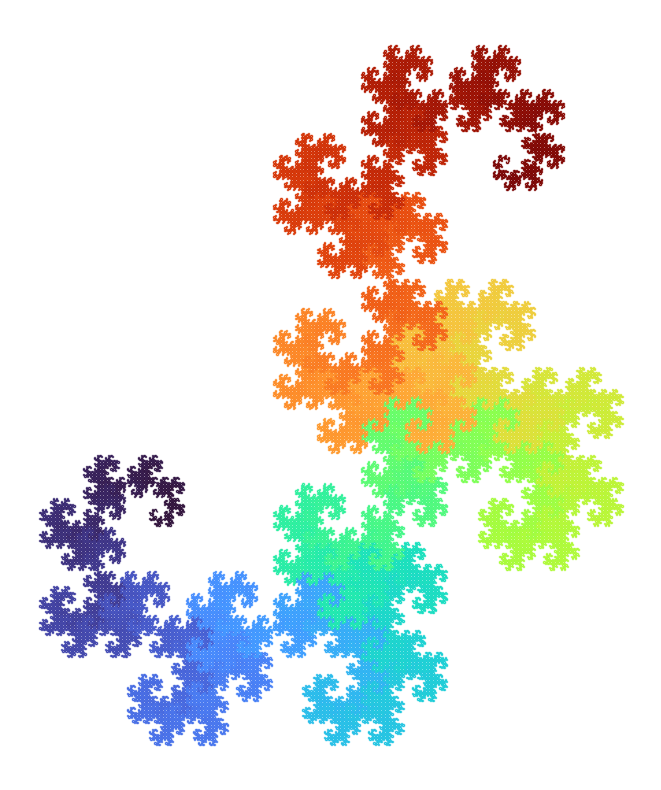

In [8]:
plot_gradient_path(dragon_path)